# Model 5: Four experts, top two, matched active parameters

**Completed full training run — Model 5.** The measured results are saved in this notebook. The training log appears under “Training and validation selection”; held-out scores, example translations, and routing diagnostics appear under “Held-out measurements”. The figures are at the end under “Saved full-run figures”.

| Measurement | Result |
|---|---:|
| Training input tokens | 59,998,213 |
| Total parameters | 39,650,304 |
| Active parameters per token | 27,079,680–27,079,680 |
| Test perplexity | 5.165 |
| Corpus BLEU (both languages) | 35.38 |
| Vietnamese → English BLEU | 40.67 |
| Japanese → English BLEU | 29.99 |

The trained weights are saved at [`full/checkpoint.pt`](full/checkpoint.pt). Open this notebook to view its saved outputs; rerunning training is unnecessary.

This notebook contains the configuration, executed correctness checks, training, evaluation, translation records, and routing diagnostics for this variant. Shared implementation cells are loaded from `../shared/implementation.ipynb`. Result status explicitly distinguishes inspection, smoke tests, and full runs.

The final checkpoint is at the end of the identical training schedule for every model. Pilot runs start independently from scratch; they select learning rate using validation NLL and are reported separately from the final training budget. No test metric selects a hyperparameter. All results below are produced by executed cells.


In [1]:
from pathlib import Path
import json, os
here=Path.cwd().resolve()
ROOT=next((p for p in [here,*here.parents,here/'part 1'] if (p/'shared'/'implementation.ipynb').exists()),None)
assert ROOT is not None, 'Set the notebook working directory inside part 1.'
for cell in json.loads((ROOT/'shared'/'implementation.ipynb').read_text())['cells']:
    if cell['cell_type']=='code' and 'definitions' in cell.get('metadata',{}).get('tags',[]):
        exec(compile(cell['source'],'shared/implementation.ipynb','exec'),globals())


In [2]:
MODEL_ID=5
PROFILE=os.environ.get('PART1_PROFILE','inspect')
assert PROFILE in ('inspect','smoke','full')
cfg=Config(variant=MODEL_ID,profile=PROFILE)
if PROFILE=='smoke':
    cfg=replace(cfg,d=64,heads=4,layers=2,hidden=256,token_budget=30_000,batch_tokens=1024,batch_examples=16,val_examples=64,eval_interval=30_000)
RUN_DIR=ROOT/f'model {MODEL_ID}'/PROFILE
print(NAMES[MODEL_ID]); display(pd.Series(asdict(cfg))); display(pd.Series(parameter_counts(cfg)))
check=run_checks(MODEL_ID); display(pd.Series(check))


4 experts; top 2; equal active parameters


variant                  5
vocab                16000
d                      512
heads                    8
layers                   6
hidden                2048
context                256
dropout                0.1
seed                    42
token_budget      60000000
batch_tokens          8192
batch_examples         128
lr                  0.0006
weight_decay           0.1
balance_coef          0.01
z_coef               0.001
eval_interval      5000000
val_examples          2048
max_new_tokens         160
profile               full
dtype: object

model                                   5
total                            39650304
active_min                       27079680
active_max                       27079680
expert_widths    [1023, 1023, 1023, 1023]
dtype: object

model                          5
causal_attention            PASS
padding                     PASS
target_loss                 PASS
KV_cache                    PASS
checkpoint                  PASS
tiny_overfit_initial    4.468045
tiny_overfit_final      0.110933
sparse_dispatch             PASS
router_gradient             PASS
dtype: object

## Training and validation selection
Two learning rates (0.0003, 0.0006) receive identical 1M-token pilot exposure, seed and validation subset. The smaller validation NLL selects the final rate; ties select the first candidate. Final training starts from scratch. Inspect the pilot table before interpreting final results. A small pilot does not establish a globally optimal hyperparameter choice.


In [3]:
pilot_results=[]; model=None; summary=None; history=None
if PROFILE in ('full','smoke'):
    manifest=json.loads((ROOT/'shared'/'data'/'manifest.json').read_text())
    tok=Tokenizer.from_file(str(ROOT/'shared'/'tokenizer_clean.json'))
    assert sha(ROOT/'shared'/'tokenizer_clean.json')==manifest['tokenizer_sha256']
    train=PairStore('train'); val=PairStore('validation'); test=PairStore('test')
    RUN_DIR.mkdir(exist_ok=True,parents=True)
    if PROFILE=='full':
        assert DEVICE.type=='cuda', 'Full training requires a functioning CUDA device; run through ADA.'
        for lr in (.0003,.0006):
            pilot_cfg=replace(cfg,lr=lr,eval_interval=1_000_000)
            folder=RUN_DIR/f'pilot_{lr}'
            checkpoint=folder/'checkpoint.pt'
            if checkpoint.exists():
                saved=torch.load(checkpoint,map_location='cpu',weights_only=False)
                assert saved['config']==asdict(pilot_cfg)
                ps=saved['summary']; del saved
            else:
                pilot,ps,ph=training_run(pilot_cfg,train,val,folder,1_000_000)
                del pilot; gc.collect(); torch.cuda.empty_cache()
            pilot_results.append({'lr':lr,'input_tokens':ps['input_tokens'],'validation_nll':ps['validation_selection']['nll'],'seconds':ps['seconds']})
        cfg=replace(cfg,lr=min(pilot_results,key=lambda r:r['validation_nll'])['lr'])
    display(pd.DataFrame(pilot_results))
    checkpoint=RUN_DIR/'checkpoint.pt'
    if checkpoint.exists():
        saved=torch.load(checkpoint,map_location='cpu',weights_only=False)
        assert saved['config']==asdict(cfg) and saved['tokenizer_sha256']==manifest['tokenizer_sha256']
        model=Transformer(cfg).to(DEVICE); model.load_state_dict(saved['model']); summary=saved['summary']; history=saved['history']; del saved
        print('Loaded completed checkpoint:',checkpoint)
    else: model,summary,history=training_run(cfg,train,val,RUN_DIR,cfg.token_budget)
    display(pd.Series(summary))
else:
    print('Inspection only. Set PART1_PROFILE=full on ADA to train; no metric is fabricated.')


model 5 | 510,228/996,387 input tokens | nll 7.4583 | 12s


model 5 | 996,387/996,387 input tokens | nll 6.7579 | 20s


validation {'nll': 6.636497999997409, 'ppl': 762.4203164447059, 'target_tokens': 42999, 'nll_vi': 6.620573896006835, 'ppl_vi': 750.375611131783, 'nll_ja': 6.652837032579924, 'ppl_ja': 774.9798527624803}


model 5 | 510,228/996,387 input tokens | nll 7.3437 | 8s


model 5 | 996,387/996,387 input tokens | nll 6.6012 | 16s


...

model 5 | 59,207,713/59,998,213 input tokens | nll 1.7364 | 1029s


model 5 | 59,671,143/59,998,213 input tokens | nll 1.7069 | 1037s


model 5 | 59,998,213/59,998,213 input tokens | nll 1.6912 | 1043s


validation {'nll': 1.657585453384017, 'ppl': 5.246627311897455, 'target_tokens': 42999, 'nll_vi': 1.5055382610862185, 'ppl_vi': 4.506578693514051, 'nll_ja': 1.8135944841278735, 'ppl_ja': 6.132450860335577}


requested_budget                                                 60000000
input_tokens                                                     59998213
target_tokens                                                    29239313
steps                                                               12473
schedule_digest         8507439435db41f0c273935f69633effe291ec668f4731...
seconds                                                        1048.19872
validation_selection    {'kind': 'validation', 'input_tokens': 5999821...
dtype: object

## Held-out measurements
Perplexity is exp(sum of English/EOS negative log likelihood / supervised token count). The table reports each language and their token-weighted aggregate. BLEU is corpus SacreBLEU with its complete signature and a paired-triplet bootstrap interval. Bootstrap uncertainty covers this evaluation sample, not variation over training seeds. Greedy generation is identical for every model, suppresses structural tokens, and reports generation limits reached.


In [4]:
result=None
if model is not None:
    validation=evaluate_nll(model,val,cfg,indices=None if PROFILE=='full' else np.arange(min(128,len(val))))
    test_metrics=evaluate_nll(model,test,cfg,indices=None if PROFILE=='full' else np.arange(min(128,len(test))))
    bleu,predictions=evaluate_bleu(model,tok,cfg,nrows=1000 if PROFILE=='full' else 16,bootstrap=300 if PROFILE=='full' else 0)
    routing=routing_diagnostics(model,test,cfg,max_pairs=1000 if PROFILE=='full' else 32)
    display(pd.DataFrame({'validation':validation,'test':test_metrics}))
    display(pd.Series(bleu)); display(pd.DataFrame(predictions).head(12))
    plot_model_results(history,routing)
    # Reproducible diagnostic strata; small strata are flagged, never used for selection.
    frame=pd.DataFrame(predictions); strata=[]
    metric=sacrebleu.metrics.BLEU()
    for (language,source),group in frame.groupby(['language','corpus_source']):
        strata.append({'language':language,'corpus_source':source,'n':len(group),'BLEU':metric.corpus_score(group.hypothesis.tolist(),[group.reference.tolist()]).score,'small_sample':len(group)<50})
    display(pd.DataFrame(strata))
    result={'model':MODEL_ID,'name':NAMES[MODEL_ID],'status':'full run completed' if PROFILE=='full' else 'SMOKE ONLY',
            'config':asdict(cfg),'parameters':parameter_counts(cfg),'training':summary,'pilots':pilot_results,
            'validation':validation,'test':test_metrics,'bleu':bleu,'routing':routing,'predictions':predictions,
            'strata':strata,'tokenizer_sha256':manifest['tokenizer_sha256'],'dataset_revision':manifest['revision'],
            'device':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU','torch_version':torch.__version__,
            'checkpoint':str(checkpoint.relative_to(ROOT)),'checkpoint_sha256':sha(checkpoint),
            'checks':check,'checkpoint_uploaded':False}
    display({'application/json':result},raw=True)
else:
    print('No experiment was executed in this notebook session.')


,validation,test
nll,1.639129e+00,1.641849e+00
ppl,5.150682e+00,5.164709e+00
target_tokens,1.043324e+06,1.038360e+06
nll_vi,1.474184e+00,1.478750e+00
ppl_vi,4.367468e+00,4.387460e+00
nll_ja,1.804075e+00,1.804947e+00
ppl_ja,6.074348e+00,6.079649e+00


triplets                                                           1000
sample_seed                                                        2026
sample_rows_sha256    50090ebaa2695798d6f45c42b28279dfa61e21b400257b...
bleu_vi                                                       40.667292
generation_cap_vi                                                     1
bleu_ja                                                       29.993694
generation_cap_ja                                                     0
bleu                                                          35.377462
signature             nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|v...
seconds                                                       79.525861
bleu_ci95                         [33.57012371148581, 37.3790415351576]
dtype: object

,row,language,source,reference,hypothesis,capped,quality_score,corpus_source
0,44,vi,Chọn đội và giải đấu yêu thích của bạn để tạo ...,Choose your favorite teams and leagues to crea...,Select your favorite team and tournament to cr...,False,0.750,CCAligned
1,63,vi,Để nói một người biết rằng tôi đang mệt mỏi củ...,Let's say someone who knows that I'm sick of u...,To say a person knows that I am tired of trust...,False,0.750,CCAligned
2,102,vi,"6. Ba, Sáu hoặc 12 quạt làm mát có sẵn","6. Three,Six or 12 cooling fans available","6. Three, six or 12 cooling fan available",False,0.750,CCAligned
3,147,vi,An toàn & Cuộc sống lâu dài,Safe& Long Life,Safety & Long Life,False,0.750,CCAligned
4,170,vi,"Yes, nó phụ thuộc vào của bạnmuasố lượng, số l...","Yes, it depends on your purchasing quantity, m...","Yes, it depends on your quantity of the more, ...",False,0.875,HPLT
5,174,vi,Mỗi bản cập nhật tích lũy mới cho SQL Server c...,Each new cumulative update for SQL Server cont...,Each update of new accumulated for SQL Server ...,False,1.000,HPLT
6,179,vi,Số mô hình: Ngọc trai 800WLED,Model Number: Pearl 800WLED,Model Number: 800WLED Filter,False,0.750,CCAligned
7,215,vi,Fabio Tognolo 17 tháng mười một 2018 2 tháng m...,Fabio Tognolo 17 November 2018 2 December 2018...,Fabio Tognolo 17 October 2018 2 December 2018 ...,False,0.750,CCAligned
8,222,vi,Lúc 9 giờ sáng trong buổi lễ khurul Trung đã đ...,At 9 am in Central khurul ceremony was held yo...,The 9-hour morning in the chess of the Chinese...,False,1.000,HPLT
9,232,vi,"Chúng tôi có đại lý ở Trung Đông, Thái Lan, Na...","We have dealer in the Middle East, Thailand, S...","We have agent in Middle East, Thailand, South ...",False,0.750,CCAligned


,layer,language,region,normalized_routing_entropy,unused_experts,max_assignment_share
0,1,vi,source,0.856908,0,0.491555
1,1,vi,English-prefix,0.799676,0,0.394913
2,1,ja,source,0.862895,0,0.492999
3,1,ja,English-prefix,0.799125,0,0.393005
4,2,vi,source,0.905025,0,0.464400
5,2,vi,English-prefix,0.899206,0,0.363788
6,2,ja,source,0.917061,0,0.462113
7,2,ja,English-prefix,0.904591,0,0.367431
8,3,vi,source,0.948367,0,0.368688
9,3,vi,English-prefix,0.934796,0,0.402037


,language,corpus_source,n,BLEU,small_sample
0,ja,CCAligned,766,32.398942,False
1,ja,HPLT,191,23.676823,False
2,ja,KDE4,11,25.438305,True
3,ja,LaboroParaCorpus,3,18.252857,True
4,ja,Tatoeba,2,9.820366,True
5,ja,Ubuntu,2,11.301601,True
6,ja,WikiMatrix,25,9.546912,True
7,vi,CCAligned,766,43.030086,False
8,vi,HPLT,191,35.609234,False
9,vi,KDE4,11,24.477309,True


## Questions for your own writeup
Use the measurements above to discuss: how capacity and active computation differ; whether validation and test patterns agree; why Vietnamese and Japanese may differ; whether confidence intervals justify a ranking; whether expert balance or language-conditioned routing changes by layer; whether a shared expert is always selected; and which generation errors involve omissions, names, numbers, repetition, or noisy references. Inspect actual source/reference/hypothesis triples. Expert usage differences alone do not prove semantic specialization. One seed and a bounded pilot search do not establish maximum attainable accuracy.

The PDF prohibits LLM assistance with the submitted writeup. Write your own analysis; these are diagnostic questions, not a submission-ready interpretation.


## Saved full-run figures

These figures use the training history and expert-routing measurements embedded above. They were rendered locally after the ADA run because ADA used a noninteractive plotting backend. No additional training occurred.

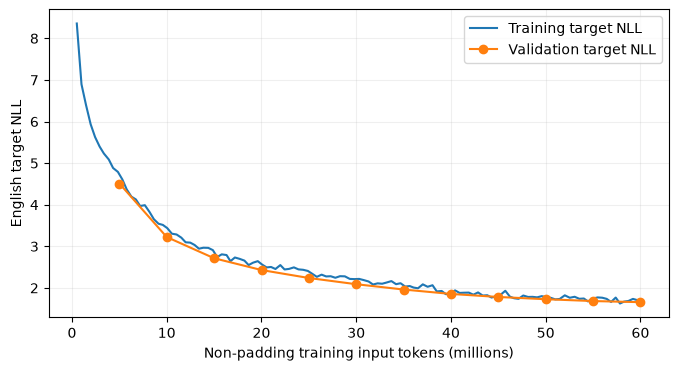

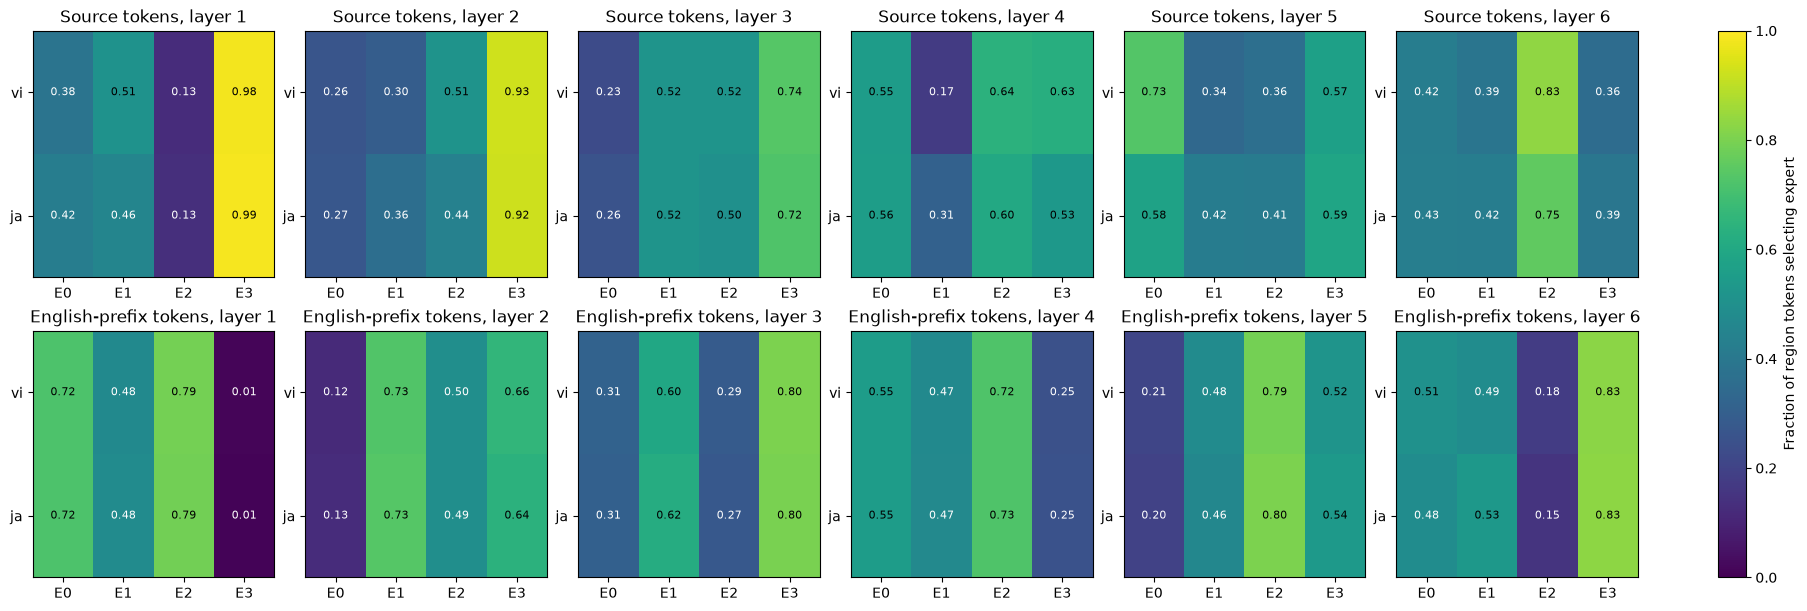

,language,layer,max_assignment_share,normalized_routing_entropy,region,unused_experts
0,vi,1,0.491555,0.856908,source,0
1,vi,1,0.394913,0.799676,English-prefix,0
2,ja,1,0.492999,0.862895,source,0
3,ja,1,0.393005,0.799125,English-prefix,0
4,vi,2,0.464400,0.905025,source,0
5,vi,2,0.363788,0.899206,English-prefix,0
6,ja,2,0.462113,0.917061,source,0
7,ja,2,0.367431,0.904591,English-prefix,0
8,vi,3,0.368688,0.948367,source,0
9,vi,3,0.402037,0.934796,English-prefix,0


In [5]:
# Recorded results are embedded in this notebook; this cell makes the figures viewable.
MODEL_ID=5
from pathlib import Path
import json
_saved=json.loads((ROOT/f"model {MODEL_ID}"/f"model_{MODEL_ID}.ipynb").read_text())
_result=next(o["data"]["application/json"] for c in _saved["cells"] for o in c.get("outputs",[]) if o.get("data",{}).get("application/json",{}).get("model")==MODEL_ID)
assert _result["status"]=="full run completed"
plot_model_results(_result["history"],_result["routing"])
